# NewsMood — 03. Sentiment de la presse et prix des actions

**Question business :** le ton de la presse financière est-il lié au rendement de l'action ?

**Méthode :**
- Données : articles nettoyés (`load_clean_articles()`), score FinBERT des **titres** (disponible pour toutes les sources).
- Chaque article est rattaché à un **jour de bourse** : heure de New York, report au lendemain après la clôture (16 h), puis au premier jour d'ouverture.
- Deux questions : **réaction** (sentiment du jour J contre rendement du jour J) et **prédiction** (sentiment du jour J contre rendement du jour J+1).

In [6]:
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.cleaning import load_clean_articles
from src.database import get_connection

articles = load_clean_articles()   # dedoublonnes + pertinents (regles de la Phase 2)

conn = get_connection()
sent = pd.read_sql(
    "SELECT article_id, score FROM sentiments WHERE model = 'finbert' AND field = 'title'", conn
)
prices = pd.read_sql("SELECT * FROM prices", conn, parse_dates=["date"])
conn.close()

# On ajoute a chaque article le score FinBERT de son titre
df = articles.merge(sent, left_on="id", right_on="article_id", how="inner")
print("Articles nettoyés :", len(articles), "| avec un score FinBERT :", len(df))

Articles nettoyés : 130 | avec un score FinBERT : 130


In [7]:
# Les jours d'ouverture de la bourse = les dates presentes dans la table des prix
trading_days = np.sort(prices["date"].unique())

# 1. Heure de New York
ny = df["published_at"].dt.tz_convert("America/New_York")

# 2. Date locale ; +1 jour si publie apres la cloture (16 h)
date_base = ny.dt.normalize().dt.tz_localize(None)
date_base = date_base + pd.to_timedelta((ny.dt.hour >= 16).astype(int), unit="D")

# 3. Premier jour de bourse >= date_base (searchsorted cherche cette position dans la liste triee)
pos = np.searchsorted(trading_days, date_base.values)
df["trading_day"] = pd.to_datetime(
    [trading_days[i] if i < len(trading_days) else pd.NaT for i in pos]
)

# Verifications
en_attente = df["trading_day"].isna().sum()
print("Articles rattachés à un jour de bourse :", df["trading_day"].notna().sum())
print("Articles en attente (jour de bourse pas encore connu) :", en_attente)
jours = sorted(df["trading_day"].dropna().unique())   # on trie les DATES, pas le texte
print("Jours de bourse utilisés :", [pd.Timestamp(j).strftime("%a %d/%m") for j in jours])

# Aucun article ne doit tomber un samedi (5) ou un dimanche (6)
assert (df["trading_day"].dropna().dt.dayofweek < 5).all(), "Un article est rattaché à un week-end !"
print("Aucun article rattaché à un week-end ✅")

Articles rattachés à un jour de bourse : 74
Articles en attente (jour de bourse pas encore connu) : 56
Jours de bourse utilisés : ['Thu 08/10', 'Fri 09/10', 'Mon 12/10', 'Tue 13/10', 'Wed 14/10', 'Thu 15/10', 'Fri 16/10']
Aucun article rattaché à un week-end ✅


## 1. Sentiment moyen par entreprise et par jour de bourse

In [8]:
# --- Rendement du lendemain (J+1) ---------------------------------------
# Pour chaque entreprise, on decale la colonne des rendements d'une ligne vers le haut :
# la ligne du jour J recoit le rendement du jour J+1.
prices = prices.sort_values(["ticker", "date"])
prices["next_return"] = prices.groupby("ticker")["daily_return"].shift(-1)

# --- Sentiment moyen par (entreprise, jour de bourse) ---------------------
daily = (
    df.dropna(subset=["trading_day"])
      .groupby(["ticker", "trading_day"])
      .agg(n_articles=("id", "count"), sentiment=("score", "mean"))
      .reset_index()
)

# --- On ajoute les prix et les rendements de ce jour ----------------------
daily = daily.merge(
    prices.rename(columns={"date": "trading_day"}),
    on=["ticker", "trading_day"], how="left",
)
daily["sentiment"] = daily["sentiment"].round(3)

print(len(daily), "lignes (entreprise × jour) | articles utilisés :", daily["n_articles"].sum())
daily[["ticker", "trading_day", "n_articles", "sentiment", "close", "daily_return", "next_return"]]

18 lignes (entreprise × jour) | articles utilisés : 74


,ticker,trading_day,n_articles,sentiment,close,daily_return,next_return
0,AAPL,2026-10-08,1,-0.043,340.42,1.1139,-1.1104
1,AAPL,2026-10-09,4,-0.175,336.64,-1.1104,1.2862
2,AAPL,2026-10-12,2,0.483,340.97,1.2862,0.0880
3,AAPL,2026-10-13,3,0.028,341.27,0.0880,0.4952
4,AAPL,2026-10-14,3,-0.166,342.96,0.4952,-0.2799
5,AAPL,2026-10-15,9,-0.109,342.00,-0.2799,0.4269
6,AAPL,2026-10-16,4,-0.036,343.46,0.4269,NaN
7,NVDA,2026-10-09,1,0.066,229.28,-0.5207,-1.2910
8,NVDA,2026-10-12,2,0.364,226.32,-1.2910,0.9721
9,NVDA,2026-10-13,4,-0.219,228.52,0.9721,-3.1595


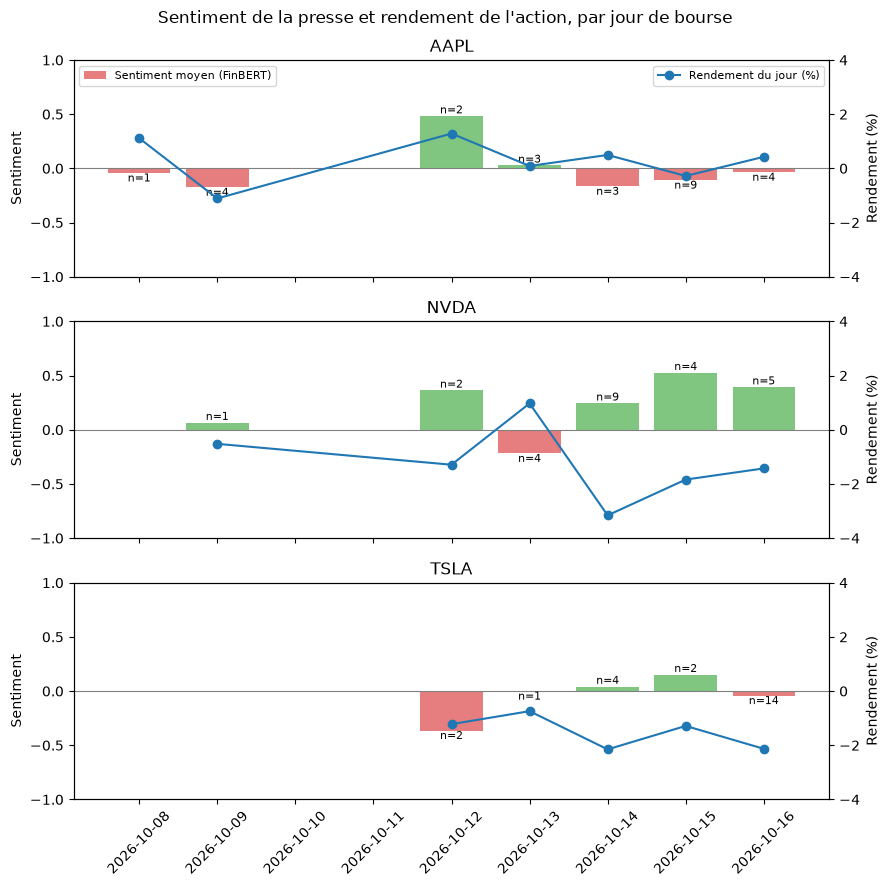

In [9]:
fig, axes = plt.subplots(3, 1, figsize=(9, 9), sharex=True)

for ax, (ticker, g) in zip(axes, daily.groupby("ticker")):
    # --- Barres : sentiment moyen du jour (axe de gauche) ---
    couleurs = ["tab:green" if s > 0 else "tab:red" for s in g["sentiment"]]
    ax.bar(g["trading_day"], g["sentiment"], color=couleurs, alpha=0.6, label="Sentiment moyen (FinBERT)")
    for x, s, n in zip(g["trading_day"], g["sentiment"], g["n_articles"]):
        # nombre d'articles au-dessus (ou en dessous) de chaque barre
        ax.annotate(f"n={n}", (x, s), ha="center", va="bottom" if s >= 0 else "top", fontsize=8)
    ax.axhline(0, color="grey", lw=0.8)
    ax.set_ylim(-1, 1)
    ax.set_ylabel("Sentiment")
    ax.set_title(ticker)

    # --- Ligne : rendement du jour (axe de droite) ---
    ax2 = ax.twinx()   # deuxieme axe vertical, qui partage le meme axe horizontal
    ax2.plot(g["trading_day"], g["daily_return"], color="tab:blue", marker="o", label="Rendement du jour (%)")
    ax2.set_ylim(-4, 4)
    ax2.set_ylabel("Rendement (%)")

    if ticker == "AAPL":   # legendes une seule fois, en haut
        ax.legend(loc="upper left", fontsize=8)
        ax2.legend(loc="upper right", fontsize=8)

axes[-1].tick_params(axis="x", rotation=45)
fig.suptitle("Sentiment de la presse et rendement de l'action, par jour de bourse")
plt.tight_layout()
plt.show()

## 2. La relation est-elle statistiquement significative ?

Corrélations de Pearson et de Spearman, les 3 entreprises regroupées. H₀ : corrélation nulle, seuil 5 %.

In [10]:
from scipy import stats

def correlations(data, cible, question):
    """Correlations de Pearson et Spearman entre le sentiment du jour et `cible`."""
    x = data.dropna(subset=[cible])            # on enleve les jours sans valeur (ex : J+1 inconnu)
    r, p_r = stats.pearsonr(x["sentiment"], x[cible])
    rho, p_rho = stats.spearmanr(x["sentiment"], x[cible])
    return {
        "question": question,
        "n_jours": len(x),
        "pearson_r": round(r, 3), "pearson_p": round(p_r, 3),
        "spearman_rho": round(rho, 3), "spearman_p": round(p_rho, 3),
    }

resultats = pd.DataFrame([
    correlations(daily, "daily_return", "Réaction (rendement du jour J)"),
    correlations(daily, "next_return", "Prédiction (rendement du jour J+1)"),
])
resultats

,question,n_jours,pearson_r,pearson_p,spearman_rho,spearman_p
0,Réaction (rendement du jour J),18,-0.235,0.348,-0.362,0.140
1,Prédiction (rendement du jour J+1),15,0.044,0.877,-0.082,0.771


## 3. Conclusions (provisoires — à relancer avec plus de données)

**Données :** 74 articles rattachés à 7 jours de bourse (du 8 au 16 octobre 2026), soit 18 points (entreprise × jour), et 15 pour la prédiction à J+1.

| Question | Pearson r (p) | Spearman ρ (p) |
| --- | --- | --- |
| Réaction (jour J) | −0,235 (0,35) | −0,362 (0,14) |
| Prédiction (jour J+1) | 0,044 (0,88) | −0,082 (0,77) |

1. **Aucune corrélation n'est significative au seuil de 5 %.** Avec 18 points, seule une corrélation supérieure à 0,47 en valeur absolue serait détectable : le test manque de puissance. On ne peut ni affirmer ni exclure un lien.
2. **Les entreprises semblent se comporter différemment :** le sentiment suit le rendement pour Apple, mais va plutôt à l'inverse pour Nvidia sur cette semaine. Le regroupement des trois entreprises suppose une relation commune, ce qui reste à vérifier.
3. **Taille d'échantillon nécessaire :** pour détecter une corrélation de 0,3 (puissance 80 %, risque 5 %), il faut environ 85 points, soit au moins 28 jours de bourse, environ 6 semaines de collecte.
4. **Limites :** peu d'articles par jour (souvent 1 à 4), mélange de sources variable selon les jours, FinBERT qui surestime le négatif, et corrélation ne veut pas dire causalité (le marché global et les publications de résultats influencent aussi les prix).

**Prochaine étape :** continuer la collecte deux fois par jour, puis relancer ce notebook (Restart puis Run All).